/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_35063/3668854835.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


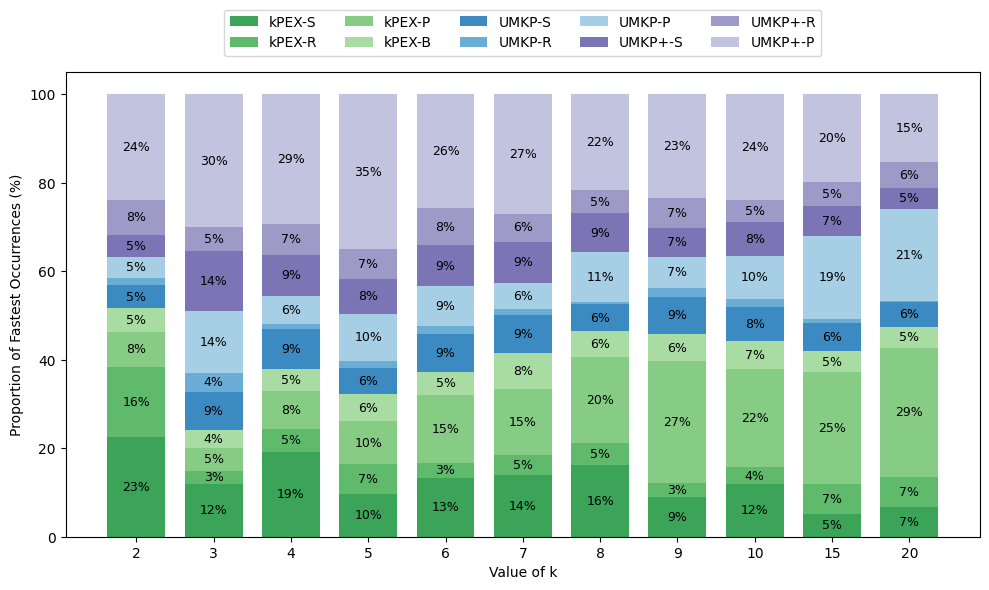

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="all")
df = df.rename(columns=lambda c: c.replace("-total", ""))

# -------------------------------------------------
# Define groups (clean, 4 groups)
# -------------------------------------------------
groups = [
    ["kPEX-S","kPEX-R", "kPEX-P", "kPEX-B"],
    ["UMKP-S","UMKP-R", "UMKP-P"],
    ["UMKP+-S","UMKP+-R", "UMKP+-P"]  
]

all_algos = sum(groups, [])

# -------------------------------------------------
# Preprocess
# -------------------------------------------------
df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)

k_values = [2,3,4,5,6,7,8,9,10,15,20]

# store percentages
results = {algo: [] for algo in all_algos}

# -------------------------------------------------
# Compute winners
# -------------------------------------------------
for k in k_values:

    df_k = df[df["k"] == k]

    if len(df_k) == 0:
        for algo in all_algos:
            results[algo].append(0)
        continue

    winners = df_k[all_algos].idxmin(axis=1)

    win_counts = winners.value_counts()
    total = len(df_k)

    for algo in all_algos:
        wins = win_counts.get(algo, 0)
        percent = (wins / total) * 100
        results[algo].append(percent)

# convert to dataframe
res_df = pd.DataFrame(results, index=k_values)

# -------------------------------------------------
# Colors (one colormap per group)
# -------------------------------------------------
cmaps = [plt.cm.Greens, plt.cm.Blues, plt.cm.Purples, plt.cm.Oranges]

colors = {}
for group, cmap in zip(groups, cmaps):
    shades = cmap(np.linspace(0.65, 0.35, len(group)))
    for algo, shade in zip(group, shades):
        colors[algo] = shade

# -------------------------------------------------
# Stacked bar plot
# -------------------------------------------------
x = np.arange(len(k_values))

fig, ax = plt.subplots(figsize=(10,6))

bottom = np.zeros(len(k_values))

for algo in all_algos:
    vals = res_df[algo].values

    ax.bar(
        x,
        vals,
        bottom=bottom,
        label=algo,
        width=0.75,
        color=colors[algo]
    )

    # annotate
    for i, v in enumerate(vals):
        if v > 3:
            ax.text(
                x[i],
                bottom[i] + v/2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                fontsize=9,
                color="black"
            )

    bottom += vals

# -------------------------------------------------
# Final styling
# -------------------------------------------------
ax.set_xlabel("Value of k")
ax.set_ylabel("Proportion of Fastest Occurrences (%)")

ax.set_xticks(x)
ax.set_xticklabels(k_values)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=5
)

plt.tight_layout()
# plt.show()

In [27]:
from IPython.display import display, HTML
pd.options.display.float_format = "{:.1f}".format
def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
cols = ["UMKP-S", "UMKP+-S"]

vals = df[cols]

best_algo = vals.idxmin(axis=1)
best_val = vals.min(axis=1)
second_val = vals.apply(lambda row: row.nsmallest(2).iloc[-1], axis=1)

result = df[(second_val >= 2 * best_val)].copy()
result["best_algo"] = best_algo
result["best_val"] = best_val
result["second_best_val"] = second_val
display_scroll(result[["dataset", "k"]+cols])


,dataset,k,UMKP-S,UMKP+-S
1,130bit,8,2.6,1.0
2,130bit,9,38.1,6.1
3,130bit,10,9.3,2.8
8,145bit,8,13.0,3.8
9,145bit,9,199.0,29.1
10,145bit,10,63.1,14.4
12,162bit,7,1597.5,336.7
18,176bit,8,1800.0,389.9
20,192bit,8,1085.0,218.4
22,208bit,8,1800.0,437.0



=== Threshold 2 Analysis ===
UMKP-P wins: 352
UMKP+-P wins: 51
Sorting by: speedup

--- Weaker side: UMKP+-P ---


,dataset,k,UMKP-P,UMKP+-P,kPEX-P,speedup
2462,orani678,7,1800.0,1.2,1.0,1525.68x
719,cit-Patents,15,1800.0,3.9,1.0,461.95x
2783,raefsky3,15,1800.0,4.9,4.6,367.05x
1868,Kuu,20,29.5,0.1,0.1,358.70x
4130,web-ClueWeb09,15,1800.0,12.5,16.6,143.44x
3896,TSOPF_FS_b162_c1,20,1800.0,14.0,4.6,128.24x
2837,reactome,5,17.4,0.2,0.2,110.54x
2873,rkat7_mat5,7,2.4,0.0,0.0,54.94x
3791,torso1,6,1800.0,36.1,36.0,49.88x
3793,torso1,10,1800.0,36.1,36.0,49.84x



--- Stronger side: UMKP-P ---


,dataset,k,UMKP-P,UMKP+-P,kPEX-P,speedup
4168,web-wikipedia_link_de,15,35.0,1750.3,288.2,50.03x
11,162bit,6,18.0,470.8,120.5,26.17x
2564,pics_ui,15,10.7,208.0,107.8,19.45x
2563,pics_ui,10,101.6,1800.0,617.0,17.72x
565,bookcrossing_rating,9,2.9,43.5,11.1,15.15x
258,amazon-ratings,15,87.2,1290.7,660.8,14.80x
15,162bit,10,124.0,1800.0,1233.6,14.52x
1770,IG5-13,15,43.7,604.9,299.7,13.85x
10,145bit,10,12.1,166.0,216.4,13.67x
143,aff-delicious-url-tag,20,146.0,1800.0,1176.2,12.33x


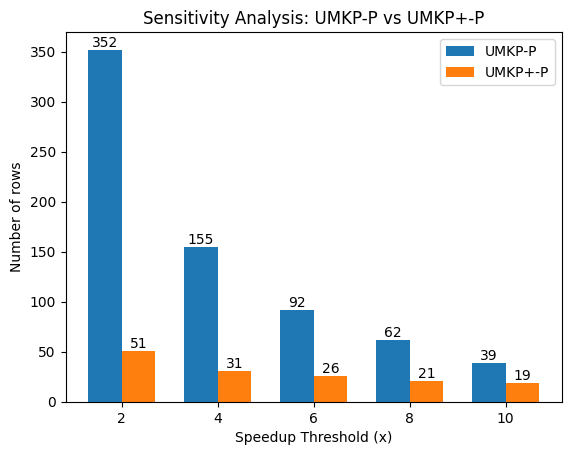

In [48]:
def compare_speedups(df, col_a, col_b,
                     thresholds=[2, 4, 6, 8, 10],
                     min_time_threshold=1.0,
                     max_len=25,
                     sort_by="speedup"):  # <-- single control point
    
    import matplotlib.pyplot as plt

    # =========================
    # Setup
    # =========================
    va = col_a.split("-")[0]
    vb = col_b.split("-")[0]

    # =========================
    # Handle zeros
    # =========================
    df = df.replace(0, 0.01)

    # =========================
    # Filter
    # =========================
    df_filtered = df[
        (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
    ].copy()

    # =========================
    # Compute speedups
    # =========================
    df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
    df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

    # =========================
    # Sorting helper (ONLY PLACE TO CHANGE LOGIC)
    # =========================
    def sort_df(df_in, side):
        if sort_by == "speedup":
            key = "speedup_a" if side == "A" else "speedup_b"
        elif sort_by == "runtime":
            key = col_a if side == "A" else col_b
        else:
            raise ValueError("sort_by must be 'speedup' or 'runtime'")
        return df_in.sort_values(by=key, ascending=False)

    # =========================
    # Threshold = first threshold
    # =========================
    threshold_check = thresholds[0]

    a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
    b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

    # =========================
    # Determine weaker & stronger
    # =========================
    if len(a_wins) < len(b_wins):
        weaker, stronger = "A", "B"
    elif len(b_wins) < len(a_wins):
        weaker, stronger = "B", "A"
    else:
        weaker = stronger = "Tie"

    # =========================
    # Formatting function
    # =========================
    def format_df(df_in, side):
        if side == "A":
            speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        else:
            speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")

        return df_in.assign(
            dataset=df_in["dataset"].apply(
                lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
            ),
            speedup=speedup_series
        )[[
            "dataset", "k",
            col_a, col_b,
            "kPEX-P",
            "speedup"
        ]]

    # =========================
    # Print summary
    # =========================
    print(f"\n=== Threshold {threshold_check} Analysis ===")
    print(f"{col_a} wins: {len(a_wins)}")
    print(f"{col_b} wins: {len(b_wins)}")
    print(f"Sorting by: {sort_by}")

    # =========================
    # Display results
    # =========================
    if weaker == "Tie":
        print("Both sides have equal wins.")

        print("\n--- Side A (>= threshold) ---")
        display_scroll(format_df(sort_df(a_wins, "A"), "A"))

        print("\n--- Side B (>= threshold) ---")
        display_scroll(format_df(sort_df(b_wins, "B"), "B"))

    else:
        if weaker == "A":
            weaker_df = sort_df(a_wins, "A")
            stronger_df = sort_df(b_wins, "B")
            weaker_name, stronger_name = col_a, col_b

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "A"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "B"))

        else:
            weaker_df = sort_df(b_wins, "B")
            stronger_df = sort_df(a_wins, "A")
            weaker_name, stronger_name = col_b, col_a

            print(f"\n--- Weaker side: {weaker_name} ---")
            display_scroll(format_df(weaker_df, "B"))

            print(f"\n--- Stronger side: {stronger_name} ---")
            display_scroll(format_df(stronger_df, "A"))

    # =========================
    # Sensitivity analysis
    # =========================
    a_counts = [(df_filtered["speedup_a"] >= t).sum() for t in thresholds]
    b_counts = [(df_filtered["speedup_b"] >= t).sum() for t in thresholds]

    # =========================
    # Plot
    # =========================
    x = range(len(thresholds))
    width = 0.35

    plt.figure()

    bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
    bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{int(height)}",
                ha='center',
                va='bottom'
            )

    add_labels(bars_a)
    add_labels(bars_b)

    plt.xticks(x, thresholds)
    plt.xlabel("Speedup Threshold (x)")
    plt.ylabel("Number of rows")
    plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")
    plt.legend()
    plt.show()
    
compare_speedups(df, "UMKP-P", "UMKP+-P")


In [56]:
mkp_cols = [f"{algo}-mkp" for algo in all_algos]

mkp_vals = df[mkp_cols].replace("x", pd.NA).apply(pd.to_numeric, errors="coerce")

real_count = mkp_vals.notna().sum(axis=1)
same_mkp = mkp_vals.nunique(axis=1, dropna=True) <= 1

df["same_mkp"] = same_mkp
df["real_mkp_count"] = real_count
df["mkp_consistent"] = same_mkp

bad_rows = df[(real_count >= 2) & (~same_mkp)]
display_scroll(bad_rows[mkp_cols])


,kPEX-S-mkp,kPEX-R-mkp,kPEX-P-mkp,kPEX-B-mkp,UMKP-S-mkp,UMKP-R-mkp,UMKP-P-mkp,UMKP+-S-mkp,UMKP+-R-mkp,UMKP+-P-mkp
